# 1. Archive Exploration

**Dataset**: Holloman, D.V., Hines, M.K., and Zoanni, D.K., 2023, Coded Water Conflict and Crisis Events in the Colorado River Basin, Derived from LexisNexis search 2005-2021: U.S. Geological Survey data release, https://doi.org/10.5066/P9X6WR7J.

**Stated Purpose**: "The data were collected to catalogue and understand water-related conflicts in the Colorado River Basin. This benefits the growing human dimension research that USGS Water Mission Area is conducting and may be a source of background information to the water availability assessment reports which USGS is producing as a series of reports over the next few years."

**Brief Description**: This dataset catalogues events (any interaction between parties that is action-defined, recorded, and made available to the public) in the Colorado River Basin from 2005-2021.

[Metadata](https://www.sciencebase.gov/catalog/file/get/63acac09d34e92aad3ca1480?f=__disk__8b%2Fdb%2Fbc%2F8bdbbc1c61caf84651f2c7af6b08288fd4f8c63b&transform=1&allowOpen=true)

# 2. Data Loading

In [2]:
# Import packages
import pandas as pd

# Display all dataframe columns
pd.set_option('display.max_columns', None)

In [3]:
# Read in data
df = pd.read_csv('data/63acac09d34e92aad3ca1480.csv')

# 3. Preliminary Data Exploration

In [4]:
# Dataset info
print(df.shape) # rows and columns
print(df.dtypes) # data types of columns
print(df.columns) # column names
df.head(5) # first 5 rows of df

(268, 48)
Event                                             int64
Search Source                                    object
Newspaper                                        object
Article Title                                    object
Duplicate                                        object
Report Date                                      object
Report Year                                     float64
Event Date                                       object
Event Day                                       float64
Event Month                                     float64
Event Year                                      float64
Conflict Present                                 object
Crisis Present                                   object
Basin                                            object
HUC6                                             object
HUC2                                             object
Place                                            object
County                                

,Event,Search Source,Newspaper,Article Title,Duplicate,Report Date,Report Year,Event Date,Event Day,Event Month,Event Year,Conflict Present,Crisis Present,Basin,HUC6,HUC2,Place,County,County FIPS,State,State FIPS,Urban or Rural,Issue Type,Event Summary,Stakeholders,Intensity Value,Comments,Related Observation Themes,Article Text Search - water quality,Article Text Search - invasive species,Article Text Search - conservation,Article Text Search - drought,Article Text Search - flood,Article Text Search - ground water depletion,Article Text Search - depletion,Article Text Search - infrastructure,Article Text Search - fish passage,Article Text Search - instream water rights,Article Text Search - water rights,Article Text Search - intergovernmental,Article Text Search - water transfers,Article Text Search - navigation,Article Text Search - fish,Article Text Search - invasive,Article Text Search - diversion,Article Text Search - water diversion,Article Text Search - instream,Article Text Search - aquatic
0,1,USGS1-50.docx,The Durango Herald (Colorado),Tribes assert water rights on Colorado River B...,False,7-Apr-22,2022.0,NaN,NaN,4.0,2022.0,Y,N,Upper San Juan,140801,14,"Durango, CO",La Plata,8067.0,CO,8,Both,Water rights more generally,Ute Mountain and Southern Ute representatives ...,"Tribal Nations, State Government, Federal Gove...",2.0,The article highlights calls for negotiation b...,Lack of tribal representation,0,0,3,7,0,0,0,1,0,0,17,0,0,0,0,0,0,0,0,0
1,2,USGS1-50.docx,"Journal, The (Cortez, Dolores, Mancos, CO)",Native American tribes assert water rights on ...,False,7-Apr-22,2022.0,NaN,NaN,4.0,2022.0,Y,N,Upper San Juan,140801,14,"Durango, CO",La Plata,8067.0,CO,8,Both,Water rights more generally,Ute Mountain and Southern Ute representatives ...,"Southern Ute Indian Tribe, Ute Mountain Tribe,...",2.0,The article highlights calls for negotiation b...,Lack of tribal representation,0,0,2,7,0,0,0,1,0,0,17,0,0,0,0,0,0,0,0,0
2,3,USGS1-50.docx,The Salt Lake Tribune,'Very positive change.' New Utah law will be a...,False,17-Mar-22,2022.0,NaN,NaN,3.0,2022.0,N,Y,Great Salt Lake,160203,16,Great Salt Lake,NaN,NaN,UT,49,Both,Instream water rights,A bill is proposed in Utah that would expand t...,"State Government, Any Water Rights Holder, Agr...",3.0,The event is the proposal of the bill at the s...,Dishonoring the absent,0,0,1,2,0,0,0,0,0,0,12,0,0,0,1,0,0,0,12,1
3,4,USGS1-50.docx,Casa Grande Dispatch (AZ),Legislation would let an Arizona tribe lease C...,False,11-Dec-21,2021.0,NaN,NaN,12.0,2021.0,N,Y,Lower Colorado,150301,15,Colorado River Indian Reservation,NaN,NaN,NaN,NaN,Rural,Water rights more generally,The Colorado River Indian Tribes Water Resilie...,"Colorado River Indian Tribes, State Government...",3.0,"Event is proposal of the bill, preliminary agr...",NaN,0,0,2,6,0,0,0,0,0,0,6,0,0,0,0,0,0,0,0,0
4,5,USGS1-50.docx,The Aspen Times (Colorado),Historically excluded from Colorado River poli...,False,19-Dec-21,2021.0,NaN,NaN,11.0,2021.0,Y,Y,Upper San Juan,140801,14,Southern Ute Indian Reservation,NaN,NaN,NaN,NaN,Rural,Intergovernmental issues,State and federal officials say that Tribal Na...,"Sothern Ute Indian Tribe, Ute Mountain Tribe, ...",-1.0,Interaction between tribal nations and state/f...,Lack of tribal representation,0,0,2,6,0,0,0,7,0,0,18,0,0,0,0,0,0,0,0,0


# 4. Location Column Descriptions

In [5]:
d = {"column": ['Place', 'State', 'Conflict Present'], "description": ['Where the event actually occurred, but also where the event’s direct implications are felt most directly. When the researchers reviewed the articles, they were looking for mentions of specific places impacted by the events. Empty cell indicates a place was not coded for this event. NA indicates a place is not referenced in the event text.', 'State Name coded from Place field. Empty cell indicates a state was not coded for this event or that the article was not coded.', 'Binary response to “Is a conflict present?” Conflict is defined here as an incompatibility of goals and various attempts of any present parties to control each other’s choices. When the researchers reviewed the articles, they were looking for evidence of this behavior in the event explained.']}
col_desc = pd.DataFrame(data = d)

# 5. String Accessor for pandas.Series

#### Code below gives a brief demonstration of using the str accessor to use the split() method for pandas.Series.

In [6]:
# CELL 1
import numpy as np
import pandas as pd 

# Example series
s = pd.Series(['California; Nevada', 'Arizona', np.nan, 'Nevada; Utah'])
s

0    California; Nevada
1               Arizona
2                   NaN
3          Nevada; Utah
dtype: object

In [7]:
# CELL 2
# str accessor (doesn't do anything by itself)
s.str

In [8]:
# CELL 3
# Use str accessor with additional methods to perform string operations
s.str.split(';')

0    [California,  Nevada]
1                [Arizona]
2                      NaN
3          [Nevada,  Utah]
dtype: object

In [9]:
# CELL 4
s.str.split('; ').explode()

0    California
0        Nevada
1       Arizona
2           NaN
3        Nevada
3          Utah
dtype: object

# 6. Examine State Codes

#### Find which states are reported in the dataset as having water conflicts

In [10]:
# Some of these values have multiple state codes in a cell, indicating a trans-boundary issue
df2 = df[['State', 'Conflict Present']]
df2 = df2.loc[df2['State'].notna()]
df2 = df2[df2['Conflict Present'] == 'Y']
df2

,State,Conflict Present
0,CO,Y
1,CO,Y
5,AZ,Y
11,OH; UT,Y
12,UT,Y
...,...,...
255,UT,Y
257,AZ,Y
258,UT,Y
262,AZ,Y


In [11]:
df['State'].value_counts()

State
AZ                            66
CO                            34
UT                            27
NV                            10
CA                             7
NM                             6
AZ; CA                         4
AZ; UT                         3
AZ; CA; CO; NV; NM; UT; WY     3
AZ; NV                         2
NV; AZ                         2
CO; AZ                         2
CO; UT; WY; NM                 2
AZ; NM                         1
CA; NV; AZ                     1
WY; UT; CO                     1
UT; CO; WY                     1
CO; WY                         1
AZ; CA; NV                     1
UT; AZ                         1
AZ; CO; NM; UT                 1
OH; UT                         1
TX                             1
Name: count, dtype: int64

# 7. Brainstorm

# 8. Exploratory Wrangling

In [12]:
df2 = df[['State', 'Conflict Present']]
df2 = df2.loc[df2['State'].notna()]
df2 = df2[df2['Conflict Present'] == 'Y']
df2

,State,Conflict Present
0,CO,Y
1,CO,Y
5,AZ,Y
11,OH; UT,Y
12,UT,Y
...,...,...
255,UT,Y
257,AZ,Y
258,UT,Y
262,AZ,Y


# 9. Find Unique State Codes

In [13]:
# df.loc[df['Conflict Present'] == 'Y', 'State'].str.split('; ').explode().unique()

states_unique = (df.loc[df['Conflict Present'] == 'Y', 'State']).str.split(';').explode().str.strip().unique()
states_unique

array(['CO', nan, 'AZ', 'OH', 'UT', 'CA', 'NV', 'WY', 'NM'], dtype=object)

# 10. Visualise Data Exploration & Discussion

<Axes: title={'center': 'Water Conflicts by State'}, xlabel='State', ylabel='Number of Conflicts'>

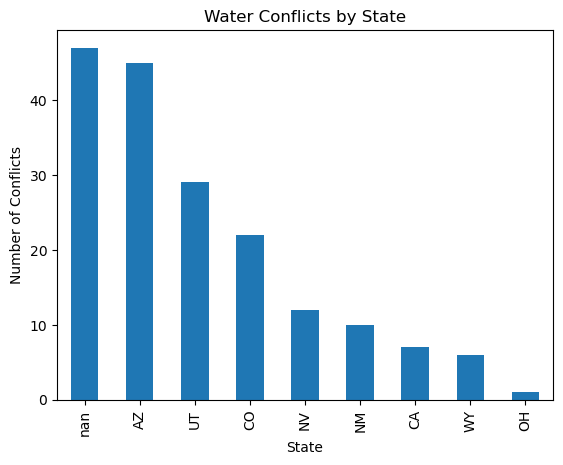

In [16]:
state_counts = (df.loc[df['Conflict Present'] == 'Y', 'State'].str.split(';').explode().str.strip().value_counts(dropna = False))

state_counts.plot(kind = 'bar', xlabel = 'State', ylabel = 'Number of Conflicts', title = 'Water Conflicts by State')